In [1]:
import os
import json
import shutil
import subprocess
from functools import partial
from multiprocessing import Pool
from pathlib import Path
from typing import Optional, Tuple, List, Literal, Union

# =============================================================================
# TYPE DEFINITIONS
# =============================================================================

# Available epoch counts from nnUNet's built-in trainers
# These are pre-defined trainer classes in nnUNet - you cannot use arbitrary values
# See: nnunetv2/training/nnUNetTrainer/variants/training_length/nnUNetTrainer_Xepochs.py
Epochs = Literal[1, 5, 10, 20, 50, 100, 250, 500, 750, 1000, 2000, 4000, 8000]

# =============================================================================
# CONFIGURATION - MODIFY THESE FOR YOUR SETUP
# =============================================================================

# Competition data path (Kaggle dataset)
INPUT_DIR = Path("/kaggle/input/vesuvius-challenge-surface-detection")

# Pre-prepared nnUNet preprocessed dataset
# Upload your preprocessed data as a Kaggle dataset to skip the 1-2 hour preprocessing step
# Set to non-existent path to force fresh preprocessing
PREPARED_PREPROCESSED_PATH = Path("/kaggle/input/vesuvius-surface-nnunet-preprocessed")

# Working directories
WORKING_DIR = Path("/kaggle/temp")  # Large intermediate files (cleared between sessions)
OUTPUT_DIR = Path("/kaggle/working")  # Final outputs (persisted)

# nnUNet directory structure (follows nnUNet conventions)
NNUNET_BASE = WORKING_DIR / "nnUNet_data"
NNUNET_RAW = NNUNET_BASE / "nnUNet_raw"  # Small - uses symlinks to competition data
NNUNET_PREPROCESSED = NNUNET_BASE / "nnUNet_preprocessed"  # Large - can use pre-prepared dataset
NNUNET_RESULTS = OUTPUT_DIR / "nnUNet_results"  # Trained models go here (persisted)

# Dataset configuration
DATASET_ID = 100  # nnUNet dataset ID (arbitrary, just needs to be consistent)
DATASET_NAME = f"Dataset{DATASET_ID:03d}_VesuviusSurface"

# =============================================================================
# TRAINING CONFIGURATION
# =============================================================================

# Fold: 0-4 for 5-fold cross-validation, "all" for training on all data
# - Use "all" for final submission (faster, uses all training data)
# - Use 0-4 for model validation and ensembling
FOLD: Union[int, str] = "all"

# Configuration: determines network architecture and resolution
# - "2d": Fastest, processes slice-by-slice (good for quick experiments)
# - "3d_lowres": Fast, handles large volumes well (NOTE: creates predicted_next_stage for cascade)
# - "3d_fullres": Best quality, single-stage (RECOMMENDED)
# - "3d_cascade_fullres": Two-stage for very large volumes (slowest, uses 3d_lowres predictions)
CONFIGURATION = "3d_fullres"

# Planner: determines network architecture variant
# - "nnUNetPlanner": Standard U-Net encoder
# - "nnUNetPlannerResEncM": ResNet encoder, medium size (RECOMMENDED - often 1-2% better)
# - "nnUNetPlannerResEncL": ResNet encoder, large (more parameters, slower)
PLANNER = "nnUNetPlannerResEncM"
PLANS_NAME = "nnUNetResEncUNetMPlans"  # Must match planner (see reference table in header)

# Number of CPU workers for preprocessing and data preparation
NUM_WORKERS = os.cpu_count() or 4

EPOCHS: Optional[Epochs] = None

# Command timeout in seconds (None for no timeout)
# Useful for Kaggle's 9-hour limit - set to e.g., 28800 (8 hours) to leave buffer
COMMAND_TIMEOUT: Optional[int] = None


def _get_gpu_count() -> int:
    """Get number of available CUDA GPUs."""
    try:
        import torch
        return torch.cuda.device_count() if torch.cuda.is_available() else 1
    except ImportError:
        return 0


NUM_GPUS: int = _get_gpu_count()


# =============================================================================
# PATH HELPER FUNCTIONS
# =============================================================================

def _get_trainer_name_simple(epochs: Optional[int]) -> str:
    """Get trainer class name based on epochs (simple version for path construction)."""
    if epochs is None or epochs == 1000:
        return "nnUNetTrainer"
    elif epochs == 1:
        return "nnUNetTrainer_1epoch"  # Special case: singular form
    else:
        return f"nnUNetTrainer_{epochs}epochs"


def get_training_output_dir(
    epochs: Optional[Epochs] = None,
    plans: str = PLANS_NAME,
    config: str = CONFIGURATION,
    fold: Union[int, str] = FOLD
) -> Path:

    _epochs = epochs if epochs is not None else EPOCHS
    trainer = _get_trainer_name_simple(_epochs)
    return NNUNET_RESULTS / DATASET_NAME / f"{trainer}__{plans}__{config}" / f"fold_{fold}"


def get_progress_image_path(
    epochs: Optional[Epochs] = None,
    plans: str = PLANS_NAME,
    config: str = CONFIGURATION,
    fold: Union[int, str] = FOLD
) -> Path:
    """Get path to training progress image (loss curves, metrics over epochs)."""
    return get_training_output_dir(epochs, plans, config, fold) / "progress.png"

## 2. Environment Setup

**Section Summary:**
Sets up nnUNet environment variables and directory structure.

**nnUNet Environment Variables:**
- `nnUNet_raw`: Where nnUNet looks for raw dataset
- `nnUNet_preprocessed`: Where preprocessed data is stored
- `nnUNet_results`: Where trained models are saved
- `nnUNet_compile`: Disable torch.compile (can cause issues)

**Pre-prepared Data Handling:**
The `_link_prepared_preprocessed()` function handles cached preprocessed data:
- Copies metadata files (JSON, PKL) that nnUNet may need to modify
- Symlinks heavy data files (NPZ, B2ND) to save space
- Handles both direct dataset paths and parent folder paths

In [2]:
def setup_environment():
    """Set up nnUNet environment variables and directories."""
    for d in [NNUNET_RAW, NNUNET_PREPROCESSED, NNUNET_RESULTS, OUTPUT_DIR]:
        d.mkdir(parents=True, exist_ok=True)
    
    os.environ["nnUNet_raw"] = str(NNUNET_RAW)
    os.environ["nnUNet_preprocessed"] = str(NNUNET_PREPROCESSED)
    os.environ["nnUNet_results"] = str(NNUNET_RESULTS)
    os.environ["nnUNet_compile"] = "true"
    
    print(f"nnUNet_raw: {NNUNET_RAW}")
    print(f"nnUNet_preprocessed: {NNUNET_PREPROCESSED}")
    print(f"nnUNet_results: {NNUNET_RESULTS}")
    print(f"nnUNet_USE_BLOSC2: {os.environ.get('nnUNet_USE_BLOSC2', 'not set')} (0=NPZ, 1=blosc2)")
    print(f"NUM_WORKERS: {NUM_WORKERS}")


def _link_prepared_preprocessed() -> bool:
    """
    Link/copy pre-prepared preprocessed data if available.
    
    Copies the folder structure and metadata files (which nnUNet may need to modify),
    but symlinks the heavy .npz/.b2nd data files to save space.
    
    Handles two possible structures:
    1. PREPARED_PREPROCESSED_PATH points directly to Dataset100_* folder
    2. PREPARED_PREPROCESSED_PATH contains Dataset100_* as subfolder
    
    Returns True if linked/copied successfully.
    """
    if not PREPARED_PREPROCESSED_PATH.exists():
        return False
    
    # Determine source directory - could be the path itself or a subfolder
    source_dir = PREPARED_PREPROCESSED_PATH
    if not (source_dir / "dataset.json").exists():
        # Look for Dataset folder inside
        dataset_folders = list(PREPARED_PREPROCESSED_PATH.glob(f"Dataset*_{DATASET_NAME.split('_')[1]}*"))
        if not dataset_folders:
            dataset_folders = list(PREPARED_PREPROCESSED_PATH.glob("Dataset*"))
        if dataset_folders:
            source_dir = dataset_folders[0]
        else:
            print(f"No dataset folder found in {PREPARED_PREPROCESSED_PATH}")
            return False
    
    target_dir = NNUNET_PREPROCESSED / DATASET_NAME
    
    if target_dir.exists():
        print(f"Preprocessed data already exists: {target_dir}")
        return True
    
    print(f"Linking preprocessed data from: {source_dir}")
    target_dir.mkdir(parents=True, exist_ok=True)
    
    # Files that nnUNet may need to write/modify - copy these
    copy_patterns = ['*.json', '*.pkl', '*.txt']
    
    # Heavy data files - symlink these  
    symlink_patterns = ['*.npz', '*.npy', '*.b2nd']
    
    copied = 0
    linked = 0
    
    for src_path in source_dir.rglob('*'):
        if src_path.is_dir():
            continue
            
        # Compute relative path and create target path
        rel_path = src_path.relative_to(source_dir)
        dst_path = target_dir / rel_path
        dst_path.parent.mkdir(parents=True, exist_ok=True)
        
        # Check if this is a heavy data file (symlink) or metadata (copy)
        is_data_file = any(src_path.match(pat) for pat in symlink_patterns)
        
        if is_data_file:
            if not dst_path.exists():
                dst_path.symlink_to(src_path.resolve())
                linked += 1
        else:
            if not dst_path.exists():
                shutil.copy2(src_path, dst_path)
                copied += 1
    
    print(f"Prepared preprocessed data: {copied} files copied, {linked} files symlinked")
    print(f"Location: {target_dir}")
    return True


setup_environment()

nnUNet_raw: /kaggle/temp/nnUNet_data/nnUNet_raw
nnUNet_preprocessed: /kaggle/temp/nnUNet_data/nnUNet_preprocessed
nnUNet_results: /kaggle/working/nnUNet_results
nnUNet_USE_BLOSC2: not set (0=NPZ, 1=blosc2)
NUM_WORKERS: 4


## 3. Installation & Imports

**Section Summary:**
Installs required packages and imports libraries.

**Key Dependencies:**
- `nnunetv2`: The nnUNet framework (includes PyTorch)
- `nibabel`: For loading NIfTI files (nnUNet's default format)
- `tifffile`: For reading/writing TIFF files (competition format)
- `matplotlib`: For visualization

**Important Notes:**
- Set `nnUNet_USE_BLOSC2=1` BEFORE importing nnunetv2 to use blosc2 format (faster)
- Blosc2 format can cause issues on some systems

In [3]:
!mkdir -p /kaggle/temp
!mkdir predictions_tiff
!pip install nnunetv2 nibabel tifffile tqdm -q --no-index -f "/kaggle/input/surface-packages-offline"

# IMPORTANT: Set this BEFORE importing nnunetv2
# Blosc2 is a newer compression format but can cause compatibility issues
os.environ["nnUNet_USE_BLOSC2"] = "1"  # Use blosc2 format (faster, smaller files)

import nibabel as nib
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# Show GPU configuration
print(f"Available GPUs: {_get_gpu_count()}")
print(f"Using NUM_GPUS={NUM_GPUS}")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
libcugraph-cu12 25.6.0 requires libraft-cu12==25.6.*, but you have libraft-cu12 25.2.0 which is incompatible.
pylibcugraph-cu12 25.6.0 requires pylibraft-cu12==25.6.*, but you have pylibraft-cu12 25.2.0 which is incompatible.
pylibcugraph-cu12 25.6.0 requires rmm-cu12==25.6.*, but you have rmm-cu12 25.2.0 which is incompatible.
Available GPUs: 2
Using NUM_GPUS=2


In [4]:
def create_spacing_json(output_path: Path, shape: tuple, spacing: tuple = (1.0, 1.0, 1.0)):
    """Create JSON sidecar with spacing info for TIFF files."""
    json_data = {"spacing": list(spacing)}
    with open(output_path, "w") as f:
        json.dump(json_data, f)


def load_nifti(path: Path) -> np.ndarray:
    """Load NIfTI file (used for loading nnUNet predictions)."""
    return nib.load(str(path)).get_fdata()


def create_dataset_json(output_dir: Path, num_training: int, file_ending: str = ".tif") -> dict:
    """Create dataset.json with ignore label support and 3D TIFF reader."""
    
    dataset_json = {
        "channel_names": {"0": "CT"},
        "labels": {"background": 0, "surface": 1, "ignore": 2},
        "numTraining": num_training,
        "file_ending": file_ending,
        "overwrite_image_reader_writer": "SimpleTiffIO"
    }
    
    json_path = output_dir / "dataset.json"
    with open(json_path, "w") as f:
        json.dump(dataset_json, f, indent=4)

    
    return dataset_json

In [5]:
def prepare_single_case(
    src_path: Path, 
    dest_path: Path, 
    json_path: Path, 
    use_symlinks: bool = True
) -> bool:
    """
    Prepare a single TIFF file for nnUNet: create symlink/copy and JSON sidecar.
    Returns True on success, False on failure.
    """
    try:
        # Get shape for JSON
        with tifffile.TiffFile(src_path) as tif:
            shape = tif.pages[0].shape if len(tif.pages) == 1 else (len(tif.pages), *tif.pages[0].shape)
        
        # Link or copy file
        if use_symlinks:
            if not dest_path.exists():
                dest_path.symlink_to(src_path.resolve())
        else:
            shutil.copy2(src_path, dest_path)
        
        # Create JSON sidecar
        create_spacing_json(json_path, shape)
        return True
        
    except Exception as e:
        print(f"Error processing {src_path.name}: {e}")
        return False


def _prepare_training_case(
    img_path: Path,
    train_labels_dir: Path,
    images_dir: Path,
    labels_dir: Path,
    use_symlinks: bool
) -> bool:
    """Worker function for parallel dataset preparation."""
    case_id = img_path.stem
    label_path = train_labels_dir / img_path.name
    
    if not label_path.exists():
        return False
    
    img_ok = prepare_single_case(
        img_path,
        images_dir / f"{case_id}_0000.tif",
        images_dir / f"{case_id}_0000.json",
        use_symlinks
    )
    
    label_ok = prepare_single_case(
        label_path,
        labels_dir / f"{case_id}.tif",
        labels_dir / f"{case_id}.json",
        use_symlinks
    )
    
    return img_ok and label_ok


def prepare_dataset(input_dir: Path, max_cases: Optional[int] = None, use_symlinks: bool = True):

    dataset_dir = NNUNET_RAW / DATASET_NAME
    images_dir = dataset_dir / "imagesTr"
    labels_dir = dataset_dir / "labelsTr"
    
    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)
    
    train_images_dir = input_dir / "train_images"
    train_labels_dir = input_dir / "train_labels"
    
    if not train_images_dir.exists():
        print(f"ERROR: {train_images_dir} not found!")
        return None
    
    image_files = sorted(train_images_dir.glob("*.tif"))
    if max_cases:
        image_files = image_files[:max_cases]
    
    print(f"Found {len(image_files)} training cases")
    print(f"Using {'symlinks' if use_symlinks else 'copy'}")
    print(f"Processing with {NUM_WORKERS} workers...")
    
    # Create worker function with fixed arguments
    worker = partial(
        _prepare_training_case,
        train_labels_dir=train_labels_dir,
        images_dir=images_dir,
        labels_dir=labels_dir,
        use_symlinks=use_symlinks
    )
    
    # Process in parallel with progress bar
    with Pool(NUM_WORKERS) as pool:
        results = list(tqdm(
            pool.imap(worker, image_files),
            total=len(image_files),
            desc="Preparing dataset"
        ))
    
    num_converted = sum(results)
    create_dataset_json(dataset_dir, num_converted, file_ending=".tif")
    
    print(f"\nDataset prepared: {num_converted} cases")
    print(f"Location: {dataset_dir}")
    
    return dataset_dir

In [6]:
def create_single_synthetic_case(
    case_id: str,
    size: Tuple[int, int, int],
    images_dir: Path,
    labels_dir: Path
):
    """Create a single synthetic training case."""
    # Create volume with structure
    volume = np.random.randn(*size).astype(np.float32) * 0.1
    
    # Add spherical shell as "surface"
    z, y, x = np.ogrid[:size[0], :size[1], :size[2]]
    center = np.array(size) // 2
    dist = np.sqrt((z - center[0])**2 + (y - center[1])**2 + (x - center[2])**2)
    shell = (dist > 15) & (dist < 20)
    volume[shell] += 1.0
    
    # Create labels
    labels = np.zeros(size, dtype=np.uint8)
    labels[shell] = 1  # Surface
    
    # Add ignore regions (label 2)
    ignore_mask = np.random.random(size) < 0.15
    labels[ignore_mask] = 2
    
    # Save as TIFF
    tifffile.imwrite(images_dir / f"{case_id}_0000.tif", volume)
    tifffile.imwrite(labels_dir / f"{case_id}.tif", labels)
    
    # Create JSON sidecars
    create_spacing_json(images_dir / f"{case_id}_0000.json", size)
    create_spacing_json(labels_dir / f"{case_id}.json", size)


def create_synthetic_dataset(num_cases: int = 5, size: Tuple[int, int, int] = (64, 64, 64)):
    """Create synthetic 3D data with ignore regions for testing (TIFF format)."""
    
    dataset_dir = NNUNET_RAW / DATASET_NAME
    images_dir = dataset_dir / "imagesTr"
    labels_dir = dataset_dir / "labelsTr"
    
    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)
    
    for i in tqdm(range(num_cases), desc="Creating synthetic data"):
        case_id = f"case_{i:03d}"
        create_single_synthetic_case(case_id, size, images_dir, labels_dir)
    
    create_dataset_json(dataset_dir, num_cases, file_ending=".tif")
    print(f"Created synthetic dataset: {dataset_dir}")
    
    return dataset_dir

# To use synthetic data instead of real data, uncomment:
# create_synthetic_dataset(num_cases=5)

In [7]:
def _run_command(
    cmd: str, 
    name: str = "Command", 
    tail_lines: int = 20,
    timeout: Optional[int] = COMMAND_TIMEOUT
) -> bool:
    """
    Execute shell command and handle output parsing.
    
    Args:
        cmd: Shell command to execute
        name: Display name for logging
        tail_lines: Number of stdout lines to show on success
        timeout: Timeout in seconds (None for no timeout)
    
    Returns:
        True if command succeeded, False otherwise
    """
    print(f"Running: {cmd}")
    if timeout:
        print(f"Timeout: {timeout}s ({timeout/3600:.1f}h)")
    
    try:
        result = subprocess.run(
            cmd, 
            shell=True, 
            capture_output=True, 
            text=True,
            timeout=timeout
        )
    except subprocess.TimeoutExpired:
        print(f"{name} TIMEOUT after {timeout}s!")
        return False
    
    if result.returncode != 0:
        print(f"{name} FAILED!")
        print(f"STDERR:\n{result.stderr[-3000:]}")
        return False
    
    print(f"{name} complete!")
    if result.stdout.strip():
        lines = result.stdout.strip().split('\n')
        print('\n'.join(lines[-tail_lines:]))
    
    return True


def run_preprocessing(
    dataset_id: int = DATASET_ID, 
    planner: str = PLANNER,
    num_workers: int = NUM_WORKERS,
    configurations: Optional[List[str]] = None,
    timeout: Optional[int] = COMMAND_TIMEOUT
) -> bool:
   
    if configurations is None:
        configurations = [CONFIGURATION]
    
    cmd = f"nnUNetv2_plan_and_preprocess -d {dataset_id:03d} -np {num_workers}"
    cmd += f" -pl {planner}"
    cmd += f" -c {' '.join(configurations)}"
    
    return _run_command(cmd, "Preprocessing", timeout=timeout)


def _get_trainer_name(epochs: Optional[Epochs]) -> str:
    """Get trainer class name based on epochs."""
    if epochs is None or epochs == 1000:
        return "nnUNetTrainer"
    elif epochs == 1:
        return "nnUNetTrainer_1epoch"
    else:
        return f"nnUNetTrainer_{epochs}epochs"


def run_training(
    dataset_id: int = DATASET_ID,
    config: str = CONFIGURATION,
    fold: Union[int, str] = FOLD,
    plans: str = PLANS_NAME,
    epochs: Optional[Epochs] = EPOCHS,
    pretrained_weights: Optional[Path] = None,
    continue_training: bool = False,
    only_run_validation: bool = False,
    disable_checkpointing: bool = False,
    npz: bool = False,
    num_gpus: int = NUM_GPUS,
    timeout: Optional[int] = COMMAND_TIMEOUT
) -> bool:
    
    trainer = _get_trainer_name(epochs)
    cmd = f"nnUNetv2_train {dataset_id:03d} {config} {fold} -p {plans} -tr {trainer}"
    
    if pretrained_weights:
        cmd += f" -pretrained_weights {pretrained_weights}"
    if continue_training:
        # Find checkpoint to resume from: prefer checkpoint_final.pth, fallback to checkpoint_best.pth
        model_dir = get_training_output_dir(epochs=epochs, plans=plans, config=config, fold=fold)
        checkpoint_final = model_dir / "checkpoint_final.pth"
        checkpoint_best = model_dir / "checkpoint_best.pth"
        if checkpoint_final.exists():
            print(f"Resuming from: {checkpoint_final}")
            cmd += " --c"
        elif checkpoint_best.exists():
            print(f"Resuming from: {checkpoint_best}")
            cmd += " --c"
        else:
            print(f"WARNING: No checkpoint found in {model_dir}, starting fresh")
    if only_run_validation:
        cmd += " --val"
    if disable_checkpointing:
        cmd += " --disable_checkpointing"
    if npz:
        cmd += " --npz"
    if num_gpus > 1:
        cmd += f" -num_gpus {num_gpus}"
    
    epochs_str = epochs if epochs else 1000
    gpu_str = f", {num_gpus} GPUs" if num_gpus > 1 else ""
    return _run_command(cmd, f"Training ({epochs_str} epochs{gpu_str})", tail_lines=30, timeout=timeout)


def run_inference(
    input_dir: Path,
    output_dir: Path,
    dataset_id: int = DATASET_ID,
    config: str = CONFIGURATION,
    fold: Union[int, str] = FOLD,
    plans: str = PLANS_NAME,
    epochs: Optional[Epochs] = EPOCHS,
    save_probabilities: bool = True,
    num_processes_preprocessing: int = 2,
    num_processes_segmentation: int = 2,
    timeout: Optional[int] = COMMAND_TIMEOUT
) -> bool:
 
    output_dir.mkdir(parents=True, exist_ok=True)
    
    trainer = _get_trainer_name(epochs)
    
    cmd = f"nnUNetv2_predict -d {dataset_id:03d} -c {config} -f {fold}"
    cmd += f" -i {input_dir} -o {output_dir} -p {plans} -tr {trainer}"
    cmd += f" -npp {num_processes_preprocessing} -nps {num_processes_segmentation}"
    cmd += " --verbose"
    
    if save_probabilities:
        cmd += " --save_probabilities"
    
    return _run_command(cmd, "Inference", timeout=timeout)

In [8]:
def prepare_test_data(input_dir: Path, output_dir: Path, use_symlinks: bool = True) -> Path:
    """Prepare test TIFF images for nnUNet inference."""
    
    output_dir.mkdir(parents=True, exist_ok=True)
    
    test_images_dir = input_dir / "test_images"
    
    if not test_images_dir.exists():
        print(f"ERROR: {test_images_dir} not found!")
        return output_dir
    
    test_files = sorted(test_images_dir.glob("*.tif"))
    print(f"Found {len(test_files)} test cases")
    print(f"Using {'symlinks' if use_symlinks else 'copy'}")
    
    for img_path in tqdm(test_files, desc="Preparing test data"):
        case_id = img_path.stem
        prepare_single_case(
            img_path,
            output_dir / f"{case_id}_0000.tif",
            output_dir / f"{case_id}_0000.json",
            use_symlinks
        )
    
    return output_dir

## 9. Inference Utilities

**Section Summary:**
Functions for converting nnUNet predictions to submission format.

**nnUNet Output Formats:**
When using our SimpleTiffIO reader with `save_probabilities=True`:
- `.npz` - Probability maps (preferred for conversion)
- `.tif` - Direct predictions (already in our format)
- `.pkl` - Metadata
- `.json` - Configuration info

**Conversion Process:**
1. Load probability maps from .npz files
2. Apply argmax to get class predictions
3. Save as uint8 TIFF (0=background, 1=surface)

In [9]:
import numpy as np
from scipy import ndimage as ndi
from skimage.morphology import remove_small_objects
from tqdm import tqdm
from pathlib import Path
import tifffile


def load_probabilities(npz_path: Path) -> np.ndarray:
    data = np.load(npz_path)
    return data['probabilities']


def create_ellipsoidal_kernel(depth_radius: int, plane_radius: int):
    """
    Generate a 3D boolean structuring element with different radii for Z and XY axes.
    Creates an ellipsoid/cylinder shape depending on radius values.
    """
    z_rad = int(depth_radius)
    xy_rad = int(plane_radius)
    
    # Handle edge case where no structure is needed
    if z_rad == 0 and xy_rad == 0:
        return None
    
    # Calculate dimensions
    z_dim = 2 * z_rad + 1
    xy_dim = 2 * xy_rad + 1
    
    # Initialize empty 3D array
    kernel = np.zeros((z_dim, xy_dim, xy_dim), dtype=bool)
    
    # Center coordinates
    cz = z_rad
    cy = cx = xy_rad
    
    # Fill the kernel based on Euclidean distance in XY plane
    for dz in range(-z_rad, z_rad + 1):
        for dy in range(-xy_rad, xy_rad + 1):
            for dx in range(-xy_rad, xy_rad + 1):
                # Check if point lies within the XY radius circle
                if dy * dy + dx * dx <= xy_rad * xy_rad:
                    kernel[cz + dz, cy + dy, cx + dx] = True
                    
    return kernel

def refine_segmentation_mask(
    prob_map,
    anchor_mask,
    thresh_low=0.25,
    thresh_high=0.75,
    radius_z=3,
    radius_xy=2,
    min_vol=250
):
    """
    Refine a segmentation mask using hysteresis thresholding, morphological closing, 
    and small component removal.
    """
    # Ensure input is float32
    prob_map = np.asarray(prob_map, dtype=np.float32)
    
    # Identify strong seeds (high confidence)
    seeds_strong = prob_map >= float(thresh_high)
    
    # Define weak region: either low confidence probability OR part of the anchor mask
    region_weak = (prob_map >= float(thresh_low)) | anchor_mask
    
    # If no strong seeds exist, return empty mask
    if not seeds_strong.any():
        return np.zeros_like(prob_map, dtype=np.uint8)
    
    # Perform hysteresis propagation (connect weak regions to strong seeds)
    # Uses 3x3x3 connectivity structure
    conn_struct = ndi.generate_binary_structure(3, 3)
    mask_propagated = ndi.binary_propagation(seeds_strong, mask=region_weak, structure=conn_struct)
    
    # Safety check: if propagation yields nothing, return empty
    if not mask_propagated.any():
        return np.zeros_like(prob_map, dtype=np.uint8)
    
    # Apply morphological closing with anisotropic kernel to fill gaps
    kernel_close = create_ellipsoidal_kernel(radius_z, radius_xy)
    if kernel_close is not None:
        mask_propagated = ndi.binary_closing(mask_propagated, structure=kernel_close)
    
    # Remove small isolated components based on volume threshold
    if int(min_vol) > 0:
        mask_propagated = remove_small_objects(
            mask_propagated.astype(bool), 
            min_size=int(min_vol)
        )
    
    return mask_propagated.astype(np.uint8)

def convert_probs_to_masks(input_folder: Path, output_folder: Path):
    """
    Batch process nnUNet probability files (.npz) into refined TIFF masks.
    
    Workflow:
      1. Load probability maps.
      2. Derive baseline foreground from argmax prediction.
      3. Apply topology-aware postprocessing (hysteresis + closing + filtering).
      4. Save result as uint8 TIFF.
    """
    # Ensure output directory exists
    output_folder.mkdir(parents=True, exist_ok=True)
    
    # Find all probability files
    prob_files = sorted(input_folder.glob("*.npz"))
    if not prob_files:
        raise FileNotFoundError(
            f"No .npz files found in {input_folder}. "
            "Please ensure inference was run with save_probabilities=True."
        )
    
    # Process each file
    for file_path in tqdm(prob_files, desc="Refining masks"):
        case_name = file_path.stem
        
        # Load data
        data_container = np.load(file_path)
        probs_all = data_container['probabilities']  # Shape: (Classes, D, H, W)
        
        # Debug logging
        print(f"Processing {case_name}: Input shape {probs_all.shape}")
        print(f"  Background: [{probs_all[0].min():.3f}, {probs_all[0].max():.3f}], mean={probs_all[0].mean():.3f}")
        print(f"  Foreground: [{probs_all[1].min():.3f}, {probs_all[1].max():.3f}], mean={probs_all[1].mean():.3f}")
        
        # Extract surface probability (assumed to be channel 1)
        prob_surface = probs_all[1]
        
        # Generate baseline anchor: any voxel not predicted as background (class 0)
        pred_argmax = np.argmax(probs_all, axis=0).astype(np.uint8)
        mask_baseline = (pred_argmax != 0)
        
        # Execute refinement pipeline
        mask_final = refine_segmentation_mask(
            prob_map=prob_surface,
            anchor_mask=mask_baseline,
            thresh_low=0.25, thresh_high=0.8,
            radius_z=3, radius_xy=2,
            min_vol=250,
        )
        
        # Save output
        out_path = output_folder / f"{case_name}.tif"
        tifffile.imwrite(out_path, mask_final)

In [10]:
def _parse_model_path(model_path: Union[str, Path, None]) -> Tuple[Optional[Path], Optional[int], Optional[str], Optional[str], Optional[str]]:

    if model_path is None:
        return None, None, None, None, None
    
    model_path = Path(model_path)
    
    # Determine model directory from path (even if doesn't exist)
    # If path ends with .pth, use parent directory
    if model_path.suffix == ".pth" or (model_path.exists() and model_path.is_file()):
        model_dir = model_path.parent
    else:
        model_dir = model_path
    
    # Try to parse folder structure
    # Expected: .../fold_X or .../TrainerName__PlansName__Config/fold_X
    try:
        parts = model_dir.parts
        
        # Find fold
        fold = None
        for part in reversed(parts):
            if part.startswith("fold_"):
                fold = part.replace("fold_", "")
                break
        
        # Find trainer__plans__config
        epochs = None
        plans = None
        config = None
        for part in parts:
            if "__" not in part:
                continue
            segments = part.split("__")
            if len(segments) >= 3:
                trainer_name = segments[0]
                plans = segments[1]
                config = segments[2]
                # Extract epochs from trainer name
                if "epochs" in trainer_name:
                    import re
                    match = re.search(r'(\d+)epochs?', trainer_name)
                    if match:
                        epochs = int(match.group(1))
                elif trainer_name == "nnUNetTrainer":
                    epochs = 1000  # Default
                break
        
        return model_dir, epochs, plans, config, fold
    except Exception:
        return model_dir, None, None, None, None

In [11]:
def full_pipeline(
    # Data options
    max_cases: Optional[int] = None,
    # Stage control
    do_preprocess: bool = True,
    do_train: bool = True,
    do_inference: bool = True,
    # Training options (all tunable parameters)
    config: str = CONFIGURATION,
    fold: Union[int, str] = FOLD,
    planner: str = PLANNER,
    plans: str = PLANS_NAME,
    epochs: Optional[Epochs] = EPOCHS,
    pretrained_weights: Optional[Path] = None,
    continue_training: bool = False,
    num_gpus: int = NUM_GPUS,
    # Inference options
    save_probabilities: bool = True,
    # External model (for inference without training)
    model_path: Optional[Union[str, Path]] = None,
    # Timeout
    timeout: Optional[int] = COMMAND_TIMEOUT,
):
   

    # 1. Setup
    print("\n[1/5] Environment setup...")
    setup_environment()
    
    # 2. Prepare raw data (always - uses symlinks, fast)
    print("\n[2/5] Preparing raw dataset (symlinks)...")
    raw_dataset_dir = NNUNET_RAW / DATASET_NAME
    if not raw_dataset_dir.exists():
        prepare_dataset(INPUT_DIR, max_cases=max_cases)
    else:
        print(f"Raw dataset already exists: {raw_dataset_dir}")
    
    # 3. Preprocessing
    if do_preprocess:
        # Check if pre-prepared preprocessed data exists
        if _link_prepared_preprocessed():
            print("\n[3/5] Using pre-prepared preprocessed data...")
        else:
            print("\n[3/5] Preprocessing...")
            success = run_preprocessing(planner=planner, configurations=[config], timeout=timeout)
            if not success:
                print("Preprocessing failed!")
                return False
    else:
        print("\n[3/5] Skipping preprocessing...")
        _link_prepared_preprocessed()  # Still link if available
    
    # 4. Training
    if do_train:
        print("\n[4/5] Training...")
        success = run_training(
            config=config,
            fold=fold,
            plans=plans,
            epochs=epochs,
            pretrained_weights=pretrained_weights,
            continue_training=continue_training,
            num_gpus=num_gpus,
            timeout=timeout
        )
        if not success:
            print("Training failed!")
            return False
    else:
        print("\n[4/5] Skipping training...")
        
        # Parse model_path to extract configuration if provided
        if model_path is not None:
            model_path = Path(model_path) if isinstance(model_path, str) else model_path
            _, parsed_epochs, parsed_plans, parsed_config, parsed_fold = _parse_model_path(model_path)
            
            # Override parameters with parsed values
            if parsed_epochs is not None:
                epochs = parsed_epochs
                print(f"  Detected epochs={epochs} from model path")
            if parsed_plans is not None:
                plans = parsed_plans
                print(f"  Detected plans={plans} from model path")
            if parsed_config is not None:
                config = parsed_config
                print(f"  Detected config={config} from model path")
            if parsed_fold is not None:
                fold = parsed_fold
                print(f"  Detected fold={fold} from model path")
            
            if model_path.exists():
                print(f"Using model: {model_path}")
            else:
                print(f"WARNING: model_path does not exist: {model_path}")
        
        # Verify model exists
        expected_model_dir = get_training_output_dir(epochs=epochs, plans=plans, config=config, fold=fold)
        expected_model_dir.mkdir(exist_ok=True, parents=True)
        checkpoint_final = expected_model_dir / "checkpoint_final.pth"
        checkpoint_best = expected_model_dir / "checkpoint_best.pth"

        if model_path and Path(model_path).exists():
            # Symlink external -> final so nnUNet finds it
            checkpoint_final.symlink_to(model_path)
            print(f"Map model: {checkpoint_final}")
        elif checkpoint_final.exists():
            print(f"Found model: {checkpoint_final}")
        elif checkpoint_best.exists():
            # Symlink best -> final so nnUNet finds it
            checkpoint_final.symlink_to(checkpoint_best)
            print(f"Found model: {checkpoint_best} (symlinked to checkpoint_final.pth)")
        elif do_inference:
            print(f"WARNING: No model found at {expected_model_dir}")
            print("  Provide model_path to a valid nnUNet checkpoint file")
    
    # 5. Inference
    if do_inference:
        print("\n[5/5] Running inference...")
        
        # Prepare test data in temp location
        test_input_dir = WORKING_DIR / "test_input"
        prepare_test_data(INPUT_DIR, test_input_dir)
        
        # Run inference
        predictions_dir = WORKING_DIR / "predictions"
        success = run_inference(
            test_input_dir, 
            predictions_dir,
            config=config,
            fold=fold,
            plans=plans,
            epochs=epochs,
            save_probabilities=save_probabilities,
            timeout=timeout
        )
        if not success:
            print("Inference failed!")
            return False
        
        # Convert predictions to TIFF
        print("\nConverting predictions to TIFF...")
        tiff_output_dir = OUTPUT_DIR / "predictions_tiff"
        convert_probs_to_masks(predictions_dir, tiff_output_dir)
        
        print(f"\nPredictions saved to: {tiff_output_dir}")
    else:
        print("\n[5/5] Skipping inference...")
    
    print("\n" + "=" * 60)
    print("Pipeline complete!")
    print("=" * 60)
    
    # Show training progress if training was done
    if do_train:
        print("\n[Visualization] Training progress:")
        show_progress(epochs=epochs, plans=plans, config=config, fold=fold)
    
    # Visualize predictions if inference was done
    if do_inference:
        print("\n[Visualization] Sample prediction:")
        visualize_predictions(num_samples=1)
    
    return True

## 11. Create Submission

**Section Summary:**
Creates a ZIP file for Kaggle submission from prediction TIFF files.

**Expected Format:**
- ZIP containing .tif prediction files
- Filenames should match test image names
- Predictions should be uint8 (0=background, 1=surface)

**Output Location:**
- `/kaggle/working/submission.zip`

In [12]:
def generate_submission(
    predictions_tiff_dir: Path = OUTPUT_DIR / "predictions_tiff",
    output_zip: Path = OUTPUT_DIR / "submission.zip",
    delete_after_zip: bool = True  # Default True to save space on Kaggle
) -> Optional[Path]:

    import zipfile
    
    if not predictions_tiff_dir.exists():
        print(f"ERROR: Predictions directory not found: {predictions_tiff_dir}")
        print("Run inference first!")
        return None
    
    tiff_files = sorted(predictions_tiff_dir.glob("*.tif"))
    
    if not tiff_files:
        print(f"No TIFF files found in {predictions_tiff_dir}")
        return None
    
    print(f"Creating submission ZIP with {len(tiff_files)} files...")
    
    with zipfile.ZipFile(output_zip, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for tiff_path in tqdm(tiff_files, desc="Zipping predictions"):
            # Add file with just the filename (no directory structure)
            zipf.write(tiff_path, tiff_path.name)
            
            if delete_after_zip:
                tiff_path.unlink()
    
    zip_size_mb = output_zip.stat().st_size / (1024 * 1024)
    print(f"Submission saved: {output_zip} ({zip_size_mb:.1f} MB)")
    
    return output_zip


# Example usage:
# generate_submission()
# generate_submission(delete_after_zip=True)  # Delete TIFFs after zipping to save space

## 12. Visualization

**Section Summary:**
Functions for visualizing training progress and predictions.

**`show_progress()`:**
- Displays nnUNet's training progress image (loss curves, metrics)
- Auto-detects correct path based on configuration

**`plot_three_axis_cuts()`:**
- Shows middle slices of XY, XZ, YZ planes
- Displays image and mask side-by-side

**`visualize_predictions()`:**
- Auto-finds predictions and corresponding input images
- Displays multiple samples if requested

In [13]:
def show_progress(
    epochs: Optional[Epochs] = None,
    plans: str = PLANS_NAME,
    config: str = CONFIGURATION,
    fold: Union[int, str] = FOLD
):
    """
    Display training progress image from nnUNet.
    
    Args:
        epochs: Number of epochs used for training (to find correct folder)
        plans: Plans name
        config: Configuration name
        fold: Fold number or "all"
    """
    progress_path = get_progress_image_path(epochs, plans, config, fold)
    
    if not progress_path.exists():
        print(f"Progress image not found: {progress_path}")
        print("Training may not have started or completed yet.")
        return
    
    from IPython.display import Image, display
    print(f"Training progress: {progress_path}")
    display(Image(filename=str(progress_path)))


def plot_three_axis_cuts(
    image_vol_path: Path,
    mask_vol_path: Path,
    figsize: tuple = (12, 15)
):
    """
    Plot middle slices of XY, XZ, and YZ planes for image volume and predicted mask.
    
    Args:
        image_vol_path: Path to input image TIFF
        mask_vol_path: Path to prediction mask TIFF
        figsize: Figure size (width, height)
    """
    print(f"Visualizing: {image_vol_path.name}")
    
    # Load volumes
    image_vol = tifffile.imread(str(image_vol_path))
    mask_vol = tifffile.imread(str(mask_vol_path)).astype(np.uint8)
    
    # Get dimensions
    d, h, w = image_vol.shape
    z_mid, y_mid, x_mid = d // 2, h // 2, w // 2
    
    # Extract slices
    slices = {
        'XY Plane (Z-axis)': (image_vol[z_mid, :, :], mask_vol[z_mid, :, :]),
        'XZ Plane (Y-axis)': (image_vol[:, y_mid, :], mask_vol[:, y_mid, :]),
        'YZ Plane (X-axis)': (image_vol[:, :, x_mid], mask_vol[:, :, x_mid])
    }
    
    fig, axes = plt.subplots(3, 2, figsize=figsize)
    for i, (plane_name, (img_slice, mask_slice)) in enumerate(slices.items()):
        # Image Volume
        axes[i, 0].imshow(img_slice, cmap='gray')
        axes[i, 0].set_title(f"{plane_name} - Image Volume")
        axes[i, 0].axis('off')
        
        # Mask
        axes[i, 1].imshow(mask_slice, cmap='gray')
        axes[i, 1].set_title(f"{plane_name} - Predicted Mask")
        axes[i, 1].axis('off')
    
    plt.tight_layout()
    plt.show()


def visualize_predictions(
    predictions_dir: Path = OUTPUT_DIR / "predictions_tiff",
    test_images_dir: Path = INPUT_DIR / "test_images",
    num_samples: int = 1
):
    """
    Visualize prediction results by showing image/mask pairs.
    
    Args:
        predictions_dir: Directory containing prediction TIFFs
        test_images_dir: Directory containing input test images
        num_samples: Number of samples to visualize
    """
    if not predictions_dir.exists():
        print(f"Predictions directory not found: {predictions_dir}")
        return
    
    predictions = sorted(predictions_dir.glob("*.tif"))
    if not predictions:
        print(f"No TIFF predictions found in {predictions_dir}")
        return
    
    print(f"Found {len(predictions)} predictions")
    
    for pred_path in predictions[:num_samples]:
        image_path = test_images_dir / pred_path.name
        if image_path.exists():
            plot_three_axis_cuts(image_path, pred_path)
        else:
            print(f"Warning: Input image not found: {image_path}")

## 13. Run Pipeline

**Section Summary:**
Execute the main pipeline and generate submission.

**Default Configuration:**
- `fold="all"` - Train on all data (no cross-validation)
- `config="3d_fullres"` - Best quality single-stage
- `epochs=1000` - Full training (can reduce to 250-500)
- `num_gpus=auto` - Uses all available GPUs

**After Running:**
1. Training progress displayed (progress.png)
2. Sample prediction visualized
3. Submission ZIP created at `/kaggle/working/submission.zip`

In [14]:
!rm -rf nnUNet_results/
!cp -r /kaggle/input/datasets/ydhdhej/nnunet-results-0229 nnUNet_results/


[1/5] Environment setup...
nnUNet_raw: /kaggle/temp/nnUNet_data/nnUNet_raw
nnUNet_preprocessed: /kaggle/temp/nnUNet_data/nnUNet_preprocessed
nnUNet_results: /kaggle/working/nnUNet_results
nnUNet_USE_BLOSC2: 1 (0=NPZ, 1=blosc2)
NUM_WORKERS: 4

[2/5] Preparing raw dataset (symlinks)...
Found 786 training cases
Using symlinks
Processing with 4 workers...


Preparing dataset: 100%|██████████| 786/786 [01:02<00:00, 12.64it/s]



Dataset prepared: 786 cases
Location: /kaggle/temp/nnUNet_data/nnUNet_raw/Dataset100_VesuviusSurface

[3/5] Skipping preprocessing...
Linking preprocessed data from: /kaggle/input/vesuvius-surface-nnunet-preprocessed
Prepared preprocessed data: 2361 files copied, 3144 files symlinked
Location: /kaggle/temp/nnUNet_data/nnUNet_preprocessed/Dataset100_VesuviusSurface

[4/5] Skipping training...
  Detected epochs=2000 from model path
  Detected plans=nnUNetResEncUNetMPlans from model path
  Detected config=3d_fullres from model path
  Detected fold=all from model path
Using model: /kaggle/working/nnUNet_results/Dataset100_VesuviusSurface/nnUNetTrainer_2000epochs__nnUNetResEncUNetMPlans__3d_fullres/fold_all/checkpoint_best.pth
Map model: /kaggle/working/nnUNet_results/Dataset100_VesuviusSurface/nnUNetTrainer_2000epochs__nnUNetResEncUNetMPlans__3d_fullres/fold_all/checkpoint_final.pth

[5/5] Running inference...
Found 1 test cases
Using symlinks


Preparing test data: 100%|██████████| 1/1 [00:00<00:00,  6.18it/s]

Running: nnUNetv2_predict -d 100 -c 3d_fullres -f all -i /kaggle/temp/test_input -o /kaggle/temp/predictions -p nnUNetResEncUNetMPlans -tr nnUNetTrainer_2000epochs -npp 2 -nps 2 --verbose --save_probabilities


Inference complete!
I am processing 0 out of 1 (max process ID is 0, we start counting with 0!)
There are 1 cases that I would like to predict
WARNING no spacing file found for images ['/kaggle/temp/test_input/1407735_0000.tif']
Assuming spacing (1, 1, 1).
None
old shape: (320, 314, 314), new_shape: [320 314 314], old_spacing: [1, 1, 1], new_spacing: [1.0, 1.0, 1.0], fn_data: functools.partial(<function resample_data_or_seg_to_shape at 0x7c674dfd40e0>, is_seg=False, order=3, order_z=0, force_separate_z=None)

Predicting 1407735:
perform_everything_on_device: True
Input shape: torch.Size([1, 320, 314, 314])
step_size: 0.5
mirror_axes: (0, 1, 2)
n_steps 27, image size is torch.Size([320, 314, 314]), tile_size [160, 160, 160], tile_step_size 0.5
steps:
[[0, 80, 160], [0, 77, 154], [0, 77, 154]]
move image to device cuda
preallocating results arrays on device cuda
Prediction done
sending off prediction to background worker for resampling and export
done with 1407735

Converting predictions

Refining masks:   0%|          | 0/1 [00:00<?, ?it/s]

Processing 1407735: Input shape (2, 320, 320, 320)
  Background: [0.017, 1.000], mean=0.941
  Foreground: [0.000, 0.983], mean=0.059


Refining masks: 100%|██████████| 1/1 [00:06<00:00,  6.53s/it]



Predictions saved to: /kaggle/working/predictions_tiff

Pipeline complete!

[Visualization] Sample prediction:
Found 1 predictions
Visualizing: 1407735.tif


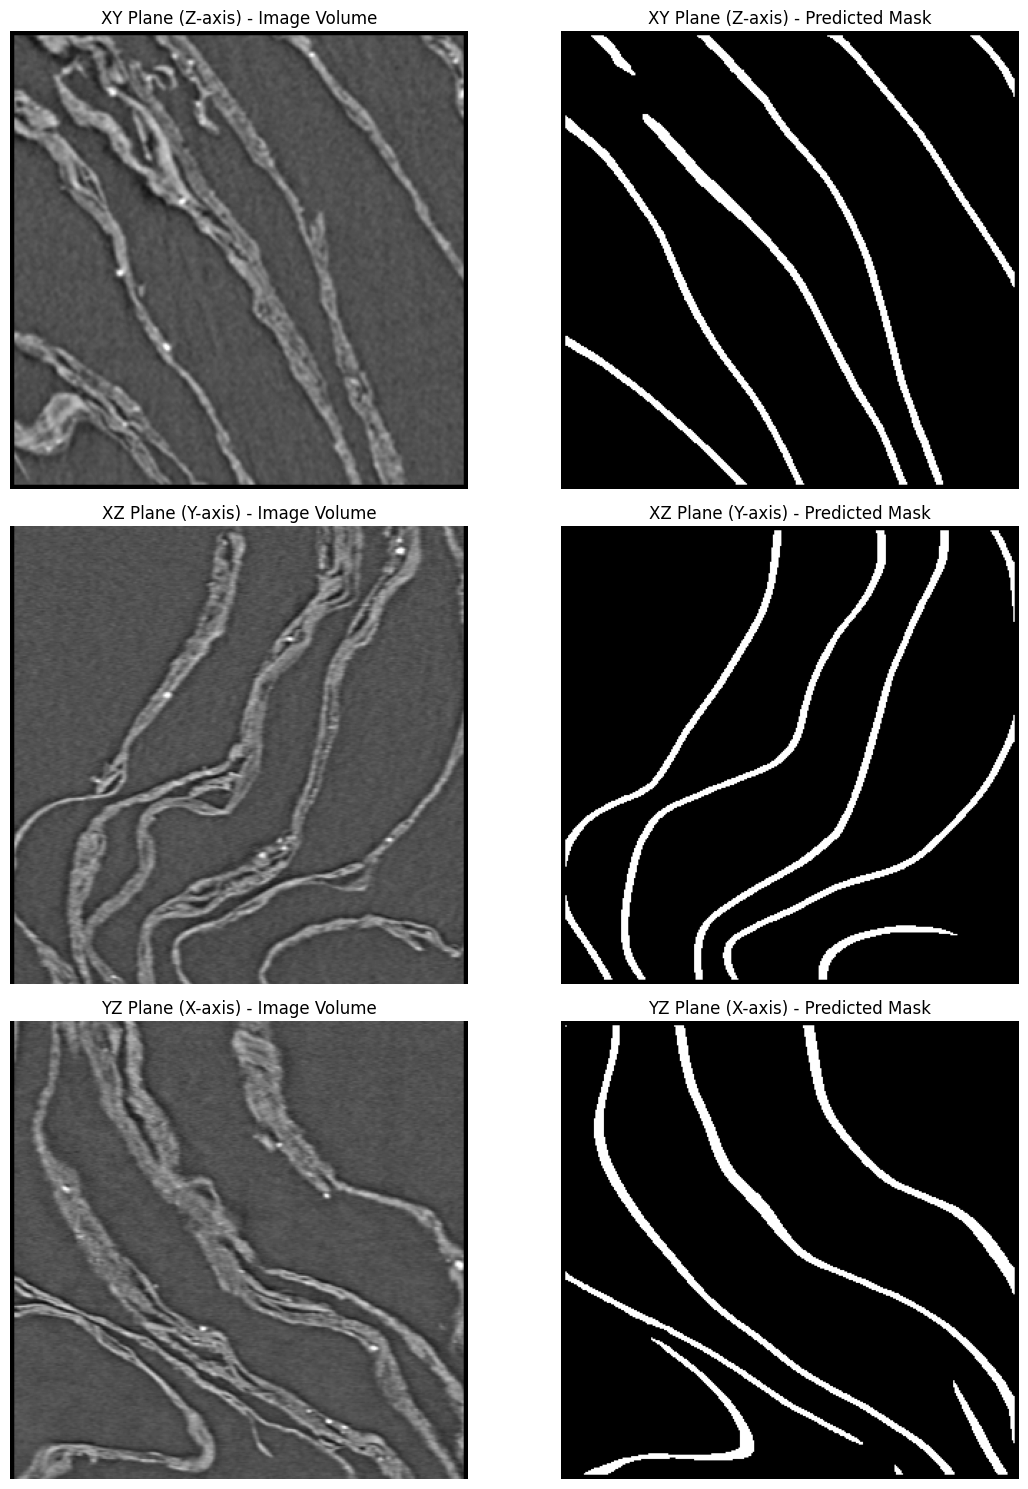

Creating submission ZIP with 1 files...


Zipping predictions: 100%|██████████| 1/1 [00:00<00:00,  2.98it/s]

Submission saved: /kaggle/working/submission.zip (0.6 MB)


PosixPath('/kaggle/working/submission.zip')

In [15]:

full_pipeline(
    do_preprocess=False, do_train=False,
    model_path="/kaggle/working/nnUNet_results/Dataset100_VesuviusSurface/nnUNetTrainer_2000epochs__nnUNetResEncUNetMPlans__3d_fullres/fold_all/checkpoint_best.pth",
)
generate_submission()